# Variant annotations


## Setup


In [1]:
import re
import sys
from pathlib import Path
import itertools
import matplotlib.colors as mcolors

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import fcluster, leaves_list, linkage
from scipy.spatial.distance import squareform

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.py").exists())
sys.path.insert(0, str(ROOT))

import config as C
import src
from src import save_plot

CATEGORY_COLOUR = {"Missense": "#009ADE", "Silent": "#9aa0a6", "Nonsense": "#FF1F5B"}

## The variant set


In [2]:
EDIT_KEY = ["chromosome", "position", "genomic_ref", "genomic_alt"]

In [3]:
annotation = pd.read_csv(C.dataset_file(C.THIS_STUDY, "annotation"), low_memory=False)
counts = annotation.drop_duplicates(["guide", *EDIT_KEY]).guide.value_counts()
single = set(counts[counts == 1].index)
variants = annotation[annotation.guide.isin(single)].drop_duplicates("guide").copy()
print(f"{len(variants):,} sgRNAs installing exactly one edit")

14,043 sgRNAs installing exactly one edit


In [4]:
variants

,guide,study,editor,gene,chromosome,position,genomic_ref,genomic_alt,guide_position,guide_edit,...,vep_rs_dbSNP,vep_transcript_basis,spliceai_ds_ag,spliceai_ds_al,spliceai_ds_dg,spliceai_ds_dl,spliceai_dp_ag,spliceai_dp_al,spliceai_dp_dg,spliceai_dp_dl
2,ACGCAGGATGCCCCCTGGGG,BECancerResistome,CBE,PIK3CD,1.0,9710452,C,T,4,C_4,...,NaN,mane,0.00,0.0,0.0,0.0,46.0,-28.0,-2.0,-10.0
9,CCCCAGGGGGCATCCTGCGT,BECancerResistome,CBE,PIK3CD,1.0,9710465,G,A,4,C_4,...,NaN,mane,0.01,0.0,0.0,0.0,2.0,-41.0,2.0,47.0
19,ATGGGGCAGTCCACCCCAGG,BECancerResistome,CBE,PIK3CD,1.0,9710475,G,A,7,C_7,...,NaN,mane,0.00,0.0,0.0,0.0,23.0,-20.0,-33.0,37.0
20,CATGGGGCAGTCCACCCCAG,BECancerResistome,CBE,PIK3CD,1.0,9710475,G,A,8,C_8,...,NaN,mane,0.00,0.0,0.0,0.0,23.0,-20.0,-33.0,37.0
21,TGGGGCAGTCCACCCCAGGG,BECancerResistome,CBE,PIK3CD,1.0,9710475,G,A,6,C_6,...,NaN,mane,0.00,0.0,0.0,0.0,23.0,-20.0,-33.0,37.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49999,AACATGGCGGCGGCGGCGGC,BECancerResistome,CBE,MAPK1,22.0,21867436,G,A,8,C_8,...,rs2145760505,mane,0.00,0.0,0.0,0.0,-47.0,37.0,2.0,-46.0
50001,CATGGCGGCGGCGGCGGCGG,BECancerResistome,CBE,MAPK1,22.0,21867436,G,A,6,C_6,...,rs2145760505,mane,0.00,0.0,0.0,0.0,-47.0,37.0,2.0,-46.0
50007,CGCCATGTTGGCTGCCGGGC,BECancerResistome,CBE,MAPK1,22.0,21867438,C,T,4,C_4,...,NaN,mane,0.00,0.0,0.0,0.0,-2.0,-34.0,-36.0,-48.0
50010,CAACATGGCGGCGGCGGCGG,BECancerResistome,CBE,MAPK1,22.0,21867441,G,A,4,C_4,...,NaN,mane,0.00,0.0,0.0,0.0,-7.0,32.0,2.0,-39.0


In [5]:
hits = pd.read_csv(C.dataset_file(C.THIS_STUDY, "hits"))
hits

,guide,condition,zscore,n_replicates,replicates_agree,control_mean,control_sd,pvalue,fdr,withheld_discordant,call
0,AAAACATCACCATTGTGACA,A375_DO_vs_plasmid,-0.088833,2,False,-0.004941,0.604938,0.889705,0.999809,False,neutral
1,AAAAGCCAAGTCTGAGACTG,A375_DO_vs_plasmid,1.589105,2,True,-0.004941,0.604938,0.008412,0.176535,False,neutral
2,AAAATAGGCGCCCACCTGCG,A375_DO_vs_plasmid,-0.313229,2,False,-0.004941,0.604938,0.610319,0.999809,False,neutral
3,AAACCAAAGGCAGAGCCACT,A375_DO_vs_plasmid,0.971237,2,True,-0.004941,0.604938,0.106596,0.732891,False,neutral
4,AAACTGTGGAGGATGTAGGA,A375_DO_vs_plasmid,0.598723,2,True,-0.004941,0.604938,0.318331,0.961485,False,neutral
...,...,...,...,...,...,...,...,...,...,...,...
545743,CGACGCTAACGCGTCGGAAT,HT29_SCH_vs_untreated,-0.071713,2,False,-0.014245,0.566362,0.919179,0.999937,False,neutral
545744,TCCCGCAAAACGATCGATCC,HT29_SCH_vs_untreated,0.736172,2,True,-0.014245,0.566362,0.185178,0.894397,False,neutral
545745,TGGTAGTACTACGACGATAG,HT29_SCH_vs_untreated,-0.568840,2,False,-0.014245,0.566362,0.327470,0.999937,False,neutral
545746,ACCCGTATCCTTTCGACGCG,HT29_SCH_vs_untreated,-0.194992,2,True,-0.014245,0.566362,0.749623,0.999937,False,neutral


In [6]:
table = hits[hits.guide.isin(single)].merge(variants, on="guide", how="left")
left = table.condition.str.split("_vs_").str[0].str.split("_")
assigned = pd.DataFrame(
    {
        "cell_line": left.str[0],
        "arm": left.str[1],
        "reference": table.condition.str.split("_vs_").str[1],
        "category": table.codon_mutation_category,
    }
)
table = pd.concat([table, assigned], axis=1)
table = table[
    ((table.arm == "DO") & (table.reference == "plasmid"))
    | ((table.arm != "DO") & (table.reference == "untreated"))
].copy()
table["phenotype"] = np.where(table.arm == "DO", "fitness", "drug response")
table["setting"] = np.where(
    table.arm == "DO",
    table.cell_line + " untreated",
    table.cell_line + " " + table.arm.map(C.ARM_LABEL),
)
DRUG_SETTINGS = sorted(table.loc[table.phenotype == "drug response", "setting"].unique())
FITNESS_SETTINGS = sorted(table.loc[table.phenotype == "fitness", "setting"].unique())
print(f"{len(DRUG_SETTINGS)} drug settings, {len(FITNESS_SETTINGS)} fitness settings")

6 drug settings, 2 fitness settings


In [7]:
table

,guide,condition,zscore,n_replicates,replicates_agree,control_mean,control_sd,pvalue,fdr,withheld_discordant,...,spliceai_dp_ag,spliceai_dp_al,spliceai_dp_dg,spliceai_dp_dl,cell_line,arm,reference,category,phenotype,setting
0,AAACTGTGGAGGATGTAGGA,A375_DO_vs_plasmid,0.598723,2,True,-0.004941,0.604938,0.318331,0.961485,False,...,-41.0,-24.0,-19.0,40.0,A375,DO,plasmid,Missense,fitness,A375 untreated
1,AACATCAGTGAGTGCTGGGG,A375_DO_vs_plasmid,-0.882887,2,False,-0.004941,0.604938,0.146697,0.817568,False,...,1.0,-32.0,0.0,1.0,A375,DO,plasmid,Silent,fitness,A375 untreated
2,AACATCGTCCACAAGACCTT,A375_DO_vs_plasmid,-0.264680,2,True,-0.004941,0.604938,0.667658,0.999809,False,...,10.0,-21.0,-21.0,15.0,A375,DO,plasmid,Silent,fitness,A375 untreated
3,AACCAAAGGCAGAGCCACTG,A375_DO_vs_plasmid,0.452002,2,True,-0.004941,0.604938,0.450036,0.999809,False,...,2.0,-13.0,21.0,48.0,A375,DO,plasmid,Missense,fitness,A375 untreated
4,AACCTGGATACCCGATTCCT,A375_DO_vs_plasmid,0.003390,2,False,-0.004941,0.604938,0.989012,0.999809,False,...,0.0,22.0,3.0,17.0,A375,DO,plasmid,Silent,fitness,A375 untreated
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
194483,GAAATGACTGAGTACAAACT,HT29_SCH_vs_untreated,-0.366470,2,False,-0.014245,0.566362,0.534003,0.999937,False,...,22.0,21.0,22.0,-29.0,HT29,SCH,untreated,Missense,drug response,HT29 SCH772984
194484,GATGTAACAAGGTGAGCATA,HT29_SCH_vs_untreated,0.432178,2,False,-0.014245,0.566362,0.430562,0.999937,False,...,33.0,-3.0,5.0,-3.0,HT29,SCH,untreated,UTR,drug response,HT29 SCH772984
194485,GTTGATACAAAACAAGCCCA,HT29_SCH_vs_untreated,1.057009,2,False,-0.014245,0.566362,0.058562,0.580799,False,...,-26.0,39.0,30.0,6.0,HT29,SCH,untreated,Missense,drug response,HT29 SCH772984
194486,TACAAAACAAGCCCACGAAC,HT29_SCH_vs_untreated,-0.409631,2,False,-0.014245,0.566362,0.485106,0.999937,False,...,44.0,11.0,35.0,-22.0,HT29,SCH,untreated,Nonsense,drug response,HT29 SCH772984


In [8]:
table.pivot_table(index="setting", columns="call", values="guide", aggfunc="count").fillna(0).astype(int)

call,neutral,resistance,sensitivity
setting,,,
A375 Linsitinib,13845,25,22
A375 Pictilisib,13695,121,76
A375 SCH772984,13834,58,0
A375 untreated,13505,47,340
HT29 Linsitinib,13634,247,11
HT29 Pictilisib,13787,72,33
HT29 SCH772984,13557,198,137
HT29 untreated,13257,187,448


In [9]:
coding = table[table.category.isin(["Missense", "Nonsense", "Silent"])].copy()
unique_variants = coding.drop_duplicates("guide")
unique_variants.category.value_counts().rename("unique guides").to_frame()

,unique guides
category,
Missense,6875
Silent,5556
Nonsense,747


## Features


In [10]:
def family_of(name):
    for family, pattern in FAMILY_PATTERNS:
        if re.search(pattern, name, re.I):
            return family
    return "other"

In [11]:
def kind_of(series):
    present = series.notna()
    if not present.any():
        return "empty"
    numeric = pd.to_numeric(series, errors="coerce")
    if numeric.notna().sum() >= 0.95 * present.sum():
        unique = numeric.nunique()
        if unique <= 2:
            return "binary"
        if unique <= 12 and (numeric.dropna() % 1 == 0).all():
            return "discrete"
        return "continuous"
    return "categorical" if series.nunique() <= 30 else "text"

In [12]:
def gene_variance_share(column):
    """Fraction of a feature's variance that lies between genes, not within them."""
    block = pd.DataFrame(
        {
            "value": pd.to_numeric(unique_variants[column], errors="coerce"),
            "gene": unique_variants.gene,
        }
    ).dropna()
    if len(block) < 50 or block.value.nunique() < 2:
        return np.nan
    grand = block.value.mean()
    group = block.groupby("gene").value
    between = (group.size() * (group.mean() - grand) ** 2).sum()
    total = ((block.value - grand) ** 2).sum()
    return between / total if total else np.nan

In [13]:
FAMILY_PATTERNS = [
    ("pathogenicity", r"SIFT|Polyphen|REVEL|MetaRNN|MetaSVM|MetaLR|AlphaMissense|ESM1b|"
                      r"EVE|VEST|MutationTaster|MutationAssessor|FATHMM|PROVEAN|CADD|"
                      r"DANN|PrimateAI|VARITY|gMVP|MutFormer|BayesDel|ClinPred|LIST|"
                      r"M-CAP|MPC|MVP|DEOGEN|Eigen|fitCons|GenoCanyon|MutScore|MisFit|"
                      r"GPN_MSA|PHACTboost|popEVE|MutPred"),
    ("conservation", r"phyloP|phastCons|GERP|SiPhy|bStatistic"),
    ("frequency", r"_AF$|^AF$|_AC$|^AC$|gnomAD|1000Gp|ExAC|ESP6500|TOPMed|UK10K|ALSPAC|"
                  r"_AN$|_nhomalt|HGVD"),
    ("splice", r"^spliceai|MaxEnt|ada_score|rf_score|dbscSNV"),
    ("structure", r"foldx|plddt|pocket|interface"),
    ("clinical", r"clinvar|CLIN|PHENO|SOMATIC|Interpro|GTEx|Geuvadis"),
]
POSITIONAL = re.compile(
    r"(^|_)(pos|position|chr|start|end|coordinate|aapos|codonpos|cds|cdna|"
    r"spliceai_dp_|residue|strand|Allele|exon|intron_rank|HGVS|Feature|Codons|"
    r"uniparc|refseq|Ensembl|transcript|UNIPROT|SWISSPROT|TREMBL)",
    re.I,
)

In [14]:
candidates = [
    c
    for c in annotation.columns
    if c.startswith(("vep_", "spliceai_"))
    or c in {"foldx_ddg", "plddt", "pocket_buriedness", "pocket_score"}
]
inventory = pd.DataFrame(
    {
        "feature": candidates,
        "kind": [kind_of(variants[c]) for c in candidates],
        "family": [family_of(c.replace("vep_", "")) for c in candidates],
        "coverage": [variants[c].notna().mean() for c in candidates],
        "distinct": [variants[c].nunique() for c in candidates],
        "positional": [bool(POSITIONAL.search(c.replace("vep_", ""))) for c in candidates],
    }
).set_index("feature")

print(f"{len(inventory)} annotation columns, {int(inventory.positional.sum())} positional or identifier")
pd.crosstab(inventory.family, inventory.kind)

600 annotation columns, 49 positional or identifier


kind,binary,categorical,continuous,discrete,empty,text
family,,,,,,
clinical,3,1,1,0,3,7
conservation,0,0,19,0,0,0
frequency,3,1,276,65,1,0
other,2,32,16,4,30,12
pathogenicity,0,9,87,0,18,2
splice,0,0,8,0,0,0


In [15]:
def modal_share_of(column):
    values = analysis_set[column]
    if not values.notna().any():
        return np.nan
    return float(values.value_counts(normalize=True).iat[0] * values.notna().mean())

In [16]:
numeric_kinds = {"continuous", "discrete", "binary"}
shortlist = inventory[
    ~inventory.positional
    & (inventory.coverage >= 0.3)
    & (inventory.distinct > 1)
].index
inventory["gene_variance"] = np.nan
inventory.loc[shortlist, "gene_variance"] = [gene_variance_share(c) for c in shortlist]

inventory["values_per_gene"] = np.nan
inventory.loc[shortlist, "values_per_gene"] = [
    unique_variants.groupby("gene")[c].nunique().mean() for c in shortlist
]
analysis_set = unique_variants[unique_variants.category == "Missense"]

In [17]:
analysis_set

,guide,condition,zscore,n_replicates,replicates_agree,control_mean,control_sd,pvalue,fdr,withheld_discordant,...,spliceai_dp_ag,spliceai_dp_al,spliceai_dp_dg,spliceai_dp_dl,cell_line,arm,reference,category,phenotype,setting
0,AAACTGTGGAGGATGTAGGA,A375_DO_vs_plasmid,0.598723,2,True,-0.004941,0.604938,0.318331,0.961485,False,...,-41.0,-24.0,-19.0,40.0,A375,DO,plasmid,Missense,fitness,A375 untreated
3,AACCAAAGGCAGAGCCACTG,A375_DO_vs_plasmid,0.452002,2,True,-0.004941,0.604938,0.450036,0.999809,False,...,2.0,-13.0,21.0,48.0,A375,DO,plasmid,Missense,fitness,A375 untreated
5,AACGTGACTGTGAAGGCACG,A375_DO_vs_plasmid,0.369200,2,False,-0.004941,0.604938,0.536260,0.999809,False,...,8.0,-39.0,7.0,37.0,A375,DO,plasmid,Missense,fitness,A375 untreated
8,AAGAGGCTGCCCGGGTTCCC,A375_DO_vs_plasmid,0.933461,2,True,-0.004941,0.604938,0.120845,0.767604,False,...,-24.0,1.0,-29.0,1.0,A375,DO,plasmid,Missense,fitness,A375 untreated
9,AAGCAAAGCACAGCTCCACT,A375_DO_vs_plasmid,-0.445868,2,True,-0.004941,0.604938,0.466076,0.999809,False,...,-14.0,-22.0,-22.0,45.0,A375,DO,plasmid,Missense,fitness,A375 untreated
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13885,CAGGATTCTTACAGAAAACA,A375_DO_vs_plasmid,-0.141382,2,False,-0.004941,0.604938,0.821555,0.999809,False,...,-7.0,-24.0,4.0,-7.0,A375,DO,plasmid,Missense,fitness,A375 untreated
13886,CTGGATACAGCTGGACAAGA,A375_DO_vs_plasmid,0.318433,2,True,-0.004941,0.604938,0.592956,0.999809,False,...,-12.0,50.0,-50.0,-15.0,A375,DO,plasmid,Missense,fitness,A375 untreated
13887,GAAATGACTGAGTACAAACT,A375_DO_vs_plasmid,0.858501,2,True,-0.004941,0.604938,0.153487,0.827043,False,...,22.0,21.0,22.0,-29.0,A375,DO,plasmid,Missense,fitness,A375 untreated
13889,GTTGATACAAAACAAGCCCA,A375_DO_vs_plasmid,0.068317,2,True,-0.004941,0.604938,0.903611,0.999809,False,...,-26.0,39.0,30.0,6.0,A375,DO,plasmid,Missense,fitness,A375 untreated


In [18]:
# how concentrated a feature is where it is measured, on the missense analysis set
inventory["modal_share"] = np.nan
inventory.loc[shortlist, "modal_share"] = [modal_share_of(c) for c in shortlist]
inventory["present_modal_share"] = np.nan
inventory.loc[shortlist, "present_modal_share"] = [
    float(analysis_set[c].value_counts(normalize=True).iat[0])
    if analysis_set[c].notna().any()
    else np.nan
    for c in shortlist
]

In [19]:
inventory.loc[shortlist].sort_values("coverage", ascending=False)

,kind,family,coverage,distinct,positional,gene_variance,values_per_gene,modal_share,present_modal_share
feature,,,,,,,,,
vep_Location,text,other,1.00000,10490,False,NaN,328.033333,0.000727,0.000727
vep_Gene,categorical,other,1.00000,30,False,NaN,1.000000,0.122909,0.122909
vep_Consequence,categorical,other,1.00000,15,False,NaN,5.966667,0.969164,0.969164
vep_IMPACT,categorical,other,1.00000,4,False,NaN,3.000000,0.997818,0.997818
vep_HGNC_ID,categorical,other,1.00000,30,False,NaN,1.000000,0.122909,0.122909
...,...,...,...,...,...,...,...,...,...
vep_gnomADe_FIN_AF,continuous,frequency,0.33433,141,False,0.006156,7.633333,0.301673,0.919734
vep_gnomADe_MID_AF,continuous,frequency,0.33433,93,False,0.006954,6.300000,0.309091,0.942350
vep_gnomADe_NFE_AF,continuous,frequency,0.33433,646,False,0.006594,45.166667,0.074327,0.226608


## Exclusions


In [20]:
# three ways a column fails to describe the variant: 
# it labels the gene, 
# it averages over a region, or 
# it says the same thing almost everywhere

PER_GENE_LIMIT = 2.0    # at most this many distinct values per gene: gene label
REGIONAL_LIMIT = 0.9    # more than this share of variance between genes
CONSTANT_LIMIT = 0.90   # one value covering more than this share of the measured edits

In [21]:
block = inventory.loc[shortlist]
numeric_block = block[block.kind.isin(numeric_kinds)]

not_numeric = block[~block.kind.isin(numeric_kinds)]
near_constant = numeric_block[numeric_block.present_modal_share > CONSTANT_LIMIT]
remaining = numeric_block.drop(index=near_constant.index)
gene_level = remaining[
    (remaining.values_per_gene <= PER_GENE_LIMIT)
    | (remaining.gene_variance > REGIONAL_LIMIT)
]
USABLE = [c for c in remaining.index if c not in set(gene_level.index)]

In [22]:
# every column, with the rule that removed it or the fact that it survived
def exclusion_reason(column):
    if inventory.positional[column]:
        return "positional or identifier"
    if inventory.kind[column] == "empty":
        return "no values"
    if column not in set(shortlist):
        if inventory.coverage[column] < 0.3:
            return "coverage below 30%"
        return "single valued"
    if column in set(not_numeric.index):
        return "not numeric"
    if column in set(near_constant.index):
        return "near constant"
    if column in set(gene_level.index):
        return "gene or transcript level"
    return "kept"


inventory["status"] = [exclusion_reason(c) for c in inventory.index]
inventory.status.value_counts().rename("columns").to_frame()

,columns
status,
coverage below 30%,351
kept,114
positional or identifier,49
no values,37
not numeric,32
near constant,10
single valued,5
gene or transcript level,2


### What each rule removes

The columns themselves, named. The order is the order the rules are applied, so every
column appears once, under the first rule that removes it.


In [23]:
ORDER = [
    "positional or identifier", "no values", "coverage below 30%", "single valued",
    "not numeric", "near constant", "gene or transcript level", "kept",
]
# one row per column, ordered by the rule that removed it. Collapsing the names into one
# cell per rule puts 351 of them in a single table cell, which is unreadable.
filtered = inventory.rename(index=lambda c: c.replace("vep_", ""))[
    ["status", "family", "kind", "coverage"]
].rename(columns={"status": "rule"})
filtered["rule"] = pd.Categorical(filtered.rule, categories=ORDER, ordered=True)
filtered = filtered.sort_values(["rule", "family", "coverage"], ascending=[True, True, False])
filtered.index.name = "feature"

with pd.option_context("display.max_rows", None):
    display(filtered)

,rule,family,kind,coverage
feature,,,,
clinvar_hgvs,positional or identifier,clinical,text,0.133091
Allele,positional or identifier,other,categorical,1.000000
transcript,positional or identifier,other,categorical,1.000000
Feature_type,positional or identifier,other,categorical,1.000000
REF_ALLELE,positional or identifier,other,categorical,1.000000
STRAND,positional or identifier,other,binary,1.000000
SWISSPROT,positional or identifier,other,categorical,1.000000
UNIPARC,positional or identifier,other,categorical,1.000000
HGVSc,positional or identifier,other,text,1.000000


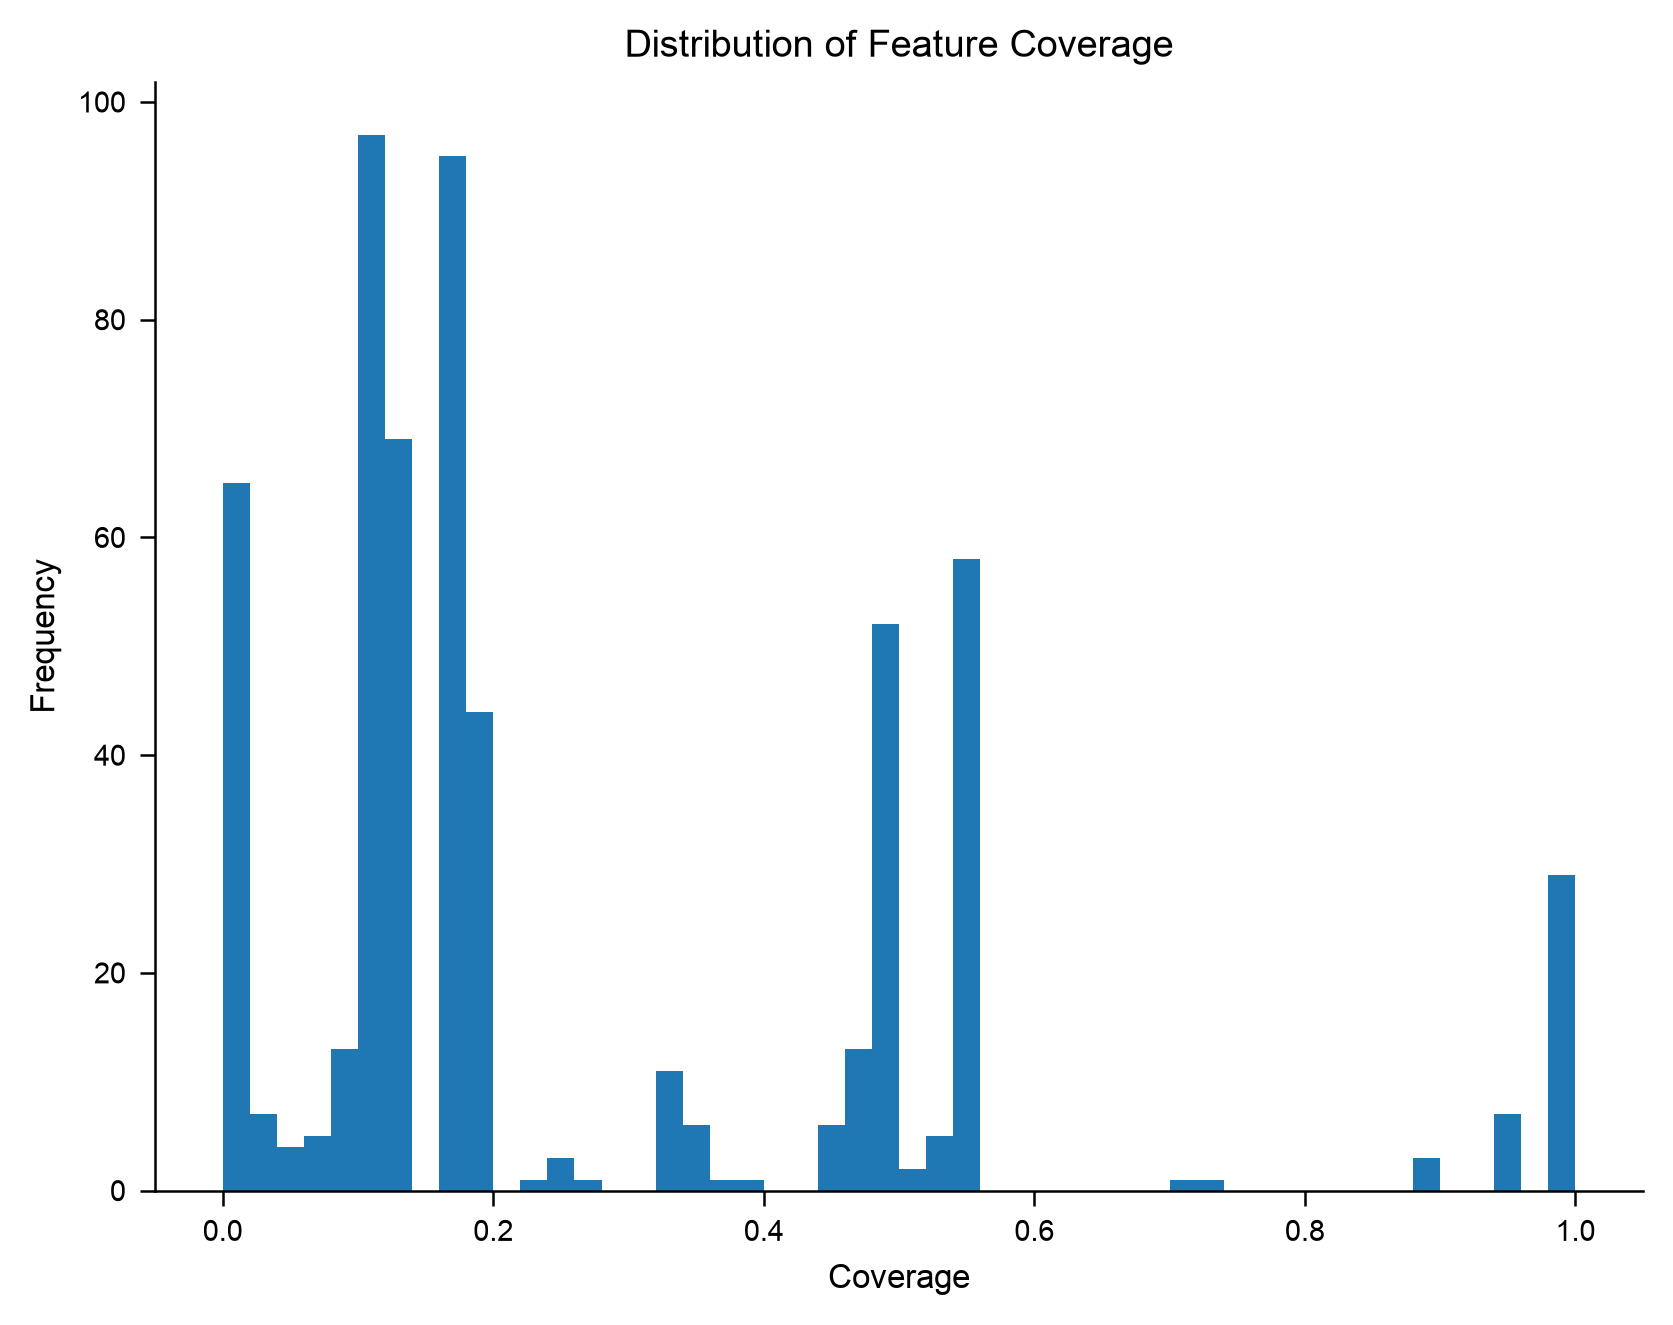

In [24]:
plt.hist(inventory.coverage, bins=50)
plt.xlabel('Coverage')
plt.ylabel('Frequency')
plt.title('Distribution of Feature Coverage')
plt.show()

In [25]:
inventory.loc[
    near_constant.index, ["family", "present_modal_share", "coverage", "distinct"]
].sort_values("present_modal_share", ascending=False)

,family,present_modal_share,coverage,distinct
feature,,,,
vep_codon_degeneracy,other,0.975453,0.545539,2
vep_gnomADe_ASJ_AF,frequency,0.955211,0.334330,80
vep_PHENO,clinical,0.946142,0.354269,2
vep_gnomADe_MID_AF,frequency,0.942350,0.334330,93
vep_gnomADe_FIN_AF,frequency,0.919734,0.334330,141
vep_TSL,other,0.913120,0.889482,3
vep_TSL_dbnsfp,other,0.913120,0.889482,3
vep_phastCons470way_mammalian,conservation,0.902325,0.545183,204
vep_phastCons470way_mammalian_rankscore,conservation,0.902325,0.545183,204


In [26]:
inventory.loc[
    gene_level.index, ["family", "gene_variance", "values_per_gene", "distinct"]
].sort_values("values_per_gene")

,family,gene_variance,values_per_gene,distinct
feature,,,,
vep_bStatistic,conservation,0.966792,11.833333,287
vep_bStatistic_converted_rankscore,conservation,0.951459,11.833333,287


### Borderline features


In [27]:
borderline = remaining[
    (remaining.gene_variance > 0.5) & (remaining.gene_variance <= REGIONAL_LIMIT)
]
inventory.loc[borderline.index, ["family", "gene_variance", "values_per_gene"]]

,family,gene_variance,values_per_gene
feature,,,
vep_GERP++_NR,conservation,0.521685,31.200000
vep_MutFormer_rankscore,pathogenicity,0.674291,158.833333
vep_MutFormer_score,pathogenicity,0.676581,172.566667


In [28]:
print(f"{len(USABLE)} usable numeric features")

114 usable numeric features


## Categorical features


In [29]:
missense = variants[variants.codon_mutation_category.eq("Missense")]

categorical = inventory[inventory.kind.eq("categorical")].copy()
categorical["levels"] = [variants[c].nunique() for c in categorical.index]
categorical["levels_in_missense"] = [missense[c].nunique() for c in categorical.index]
categorical["modal_in_missense"] = [
    missense[c].value_counts(normalize=True).max() if missense[c].notna().any() else np.nan
    for c in categorical.index
]

In [30]:
GENE_COUNT = variants.gene.nunique()
ARCHAIC = ("Neandertal", "Denisova", "Ancestral_allele")
ALLELE = ("Allele", "REF_ALLELE", "ref", "alt")


def categorical_verdict(column, row):
    stem = column.replace("vep_", "")
    if row.positional:
        return "identifier"
    if stem.endswith("_pred"):
        return "threshold on its own score"
    if row.levels <= 1:
        return "single valued"
    if row.levels == GENE_COUNT:
        return "gene identity"
    if row.levels_in_missense <= 1 or row.modal_in_missense > 0.95:
        return "constant within missense"
    if stem in ALLELE:
        # two levels for a cytosine editor is the strand, not the substitution
        return "allele or strand encoding"
    if stem.endswith(("_POP", "_POPS")):
        return "population label"
    if "clnsig" in stem.lower():
        # a curated clinical call: circular with the databases the scores train on
        return "clinical label"
    if any(word in stem for word in ARCHAIC):
        return "archaic or ancestral allele"
    return "recovered as dummies"


categorical["verdict"] = [
    categorical_verdict(c, categorical.loc[c]) for c in categorical.index
]
categorical.verdict.value_counts().rename("columns").to_frame()

,columns
verdict,
identifier,10
threshold on its own score,9
gene identity,5
single valued,5
archaic or ancestral allele,4
recovered as dummies,3
constant within missense,2
population label,2
allele or strand encoding,2


In [31]:
categorical[["levels", "levels_in_missense", "modal_in_missense", "verdict"]].sort_values(
    ["verdict", "levels_in_missense"], ascending=[True, False]
)

,levels,levels_in_missense,modal_in_missense,verdict
feature,,,,
vep_alt,2,2,0.537475,allele or strand encoding
vep_ref,2,2,0.537214,allele or strand encoding
vep_AltaiNeandertal,5,5,0.437014,archaic or ancestral allele
vep_ChagyrskayaNeandertal,4,4,0.437158,archaic or ancestral allele
vep_VindijiaNeandertal,4,4,0.437158,archaic or ancestral allele
vep_Denisova,3,3,0.436581,archaic or ancestral allele
vep_clinvar_clnsig,9,9,0.758319,clinical label
vep_Consequence,15,3,0.969155,constant within missense
vep_IMPACT,4,2,0.997838,constant within missense


### Recovered as dummies


In [32]:
RECOVERED = list(categorical.index[categorical.verdict.eq("recovered as dummies")])
dummies = pd.get_dummies(
    variants[RECOVERED].astype("string"), prefix_sep="=", dummy_na=False, dtype=float
)
occupancy = dummies.loc[missense.index].mean()
DUMMY_FEATURES = list(occupancy[occupancy >= 0.01].index)
variants[DUMMY_FEATURES] = dummies[DUMMY_FEATURES]

# the association frames are built from `table`, so the dummies have to reach it too
dummy_by_guide = variants.set_index("guide")[DUMMY_FEATURES]
for frame in (table, coding):
    frame[DUMMY_FEATURES] = dummy_by_guide.reindex(frame.guide).to_numpy()

In [33]:
pd.DataFrame(
    {
        "share of missense edits": occupancy[DUMMY_FEATURES],
        "source": [name.split("=")[0].replace("vep_", "") for name in DUMMY_FEATURES],
    }
).sort_values("share of missense edits", ascending=False)

,share of missense edits,source
vep_am_class=likely_benign,0.478956,am_class
vep_am_class=likely_pathogenic,0.397377,am_class
vep_aaref=A,0.209715,aaref
vep_aaalt=I,0.181897,aaalt
vep_aaalt=N,0.167916,aaalt
vep_aaref=S,0.125252,aaref
vep_aaref=R,0.119487,aaref
vep_am_class=ambiguous,0.118910,am_class
vep_aaalt=T,0.107236,aaalt
vep_aaalt=V,0.102479,aaalt


In [34]:
print(f"{len(RECOVERED)} categorical columns -> {dummies.shape[1]} levels -> "
      f"{len(DUMMY_FEATURES)} dummies carried into the association analysis")

3 categorical columns -> 36 levels -> 31 dummies carried into the association analysis


## Redundant encodings


In [35]:
def partner_of(column):
    """The score column a rank score derives from, under either naming convention."""
    stem = column.replace("vep_", "")
    for suffix, replacement in [
        ("_converted_rankscore", "_score"),
        ("_rankscore", "_score"),
        ("_converted_rankscore", ""),
        ("_rankscore", ""),
    ]:
        if stem.endswith(suffix):
            base = stem[: -len(suffix)]
            for candidate in [f"vep_{base}{replacement}", f"vep_{base}"]:
                if candidate in annotation.columns and candidate != column:
                    return candidate
    return None

In [36]:
rankscore_columns = [c for c in inventory.index if c.endswith("rankscore")]
pairs = [(partner_of(c), c) for c in rankscore_columns]
pairs = [(s, r) for s, r in pairs if s]
agreement = []
for score, rank in pairs:
    both = pd.DataFrame(
        {
            "score": pd.to_numeric(variants[score], errors="coerce"),
            "rank": pd.to_numeric(variants[rank], errors="coerce"),
        }
    ).dropna()
    if len(both) > 50:
        ambiguous = int((both.groupby("score")["rank"].nunique() > 1).sum())
        agreement.append(
            {
                "predictor": score.replace("vep_", ""),
                "spearman": both.score.corr(both["rank"], method="spearman"),
                "distinct_scores": both.score.nunique(),
                "scores_mapping_to_many_ranks": ambiguous,
                "n": len(both),
            }
        )
agreement = pd.DataFrame(agreement).sort_values("spearman", key=abs)

In [37]:
agree = int((agreement.spearman.abs() > 0.999).sum())
print(f"{len(rankscore_columns)} rank score columns, {len(agreement)} paired with their score")
print(f"{agree} rank exactly as their score does, {len(agreement) - agree} do not")

50 rank score columns, 50 paired with their score
41 rank exactly as their score does, 9 do not


## Agreement between independent predictors


In [38]:
def numeric(column):
    return pd.to_numeric(variants.get(column), errors="coerce")

In [39]:
COMPARISONS = [
    ("vep_CADD_phred", "vep_REVEL_score", "CADD vs REVEL"),
    ("vep_AlphaMissense_score", "vep_REVEL_score", "AlphaMissense vs REVEL"),
    ("vep_AlphaMissense_score", "vep_ESM1b_score", "AlphaMissense vs ESM1b"),
    ("vep_SIFT_score", "vep_SIFT4G_score", "SIFT vs SIFT4G"),
    ("vep_Polyphen2_HDIV_score", "vep_Polyphen2_HVAR_score", "PolyPhen2 HDIV vs HVAR"),
    ("vep_GERP++_RS", "vep_phyloP100way_vertebrate", "GERP++ vs phyloP"),
    ("vep_phastCons100way_vertebrate", "vep_phyloP100way_vertebrate",
     "phastCons vs phyloP"),
    ("vep_CADD_phred", "vep_AlphaMissense_score", "CADD vs AlphaMissense"),
]
present = [
    (a, b, label) for a, b, label in COMPARISONS
    if a in variants.columns and b in variants.columns
]

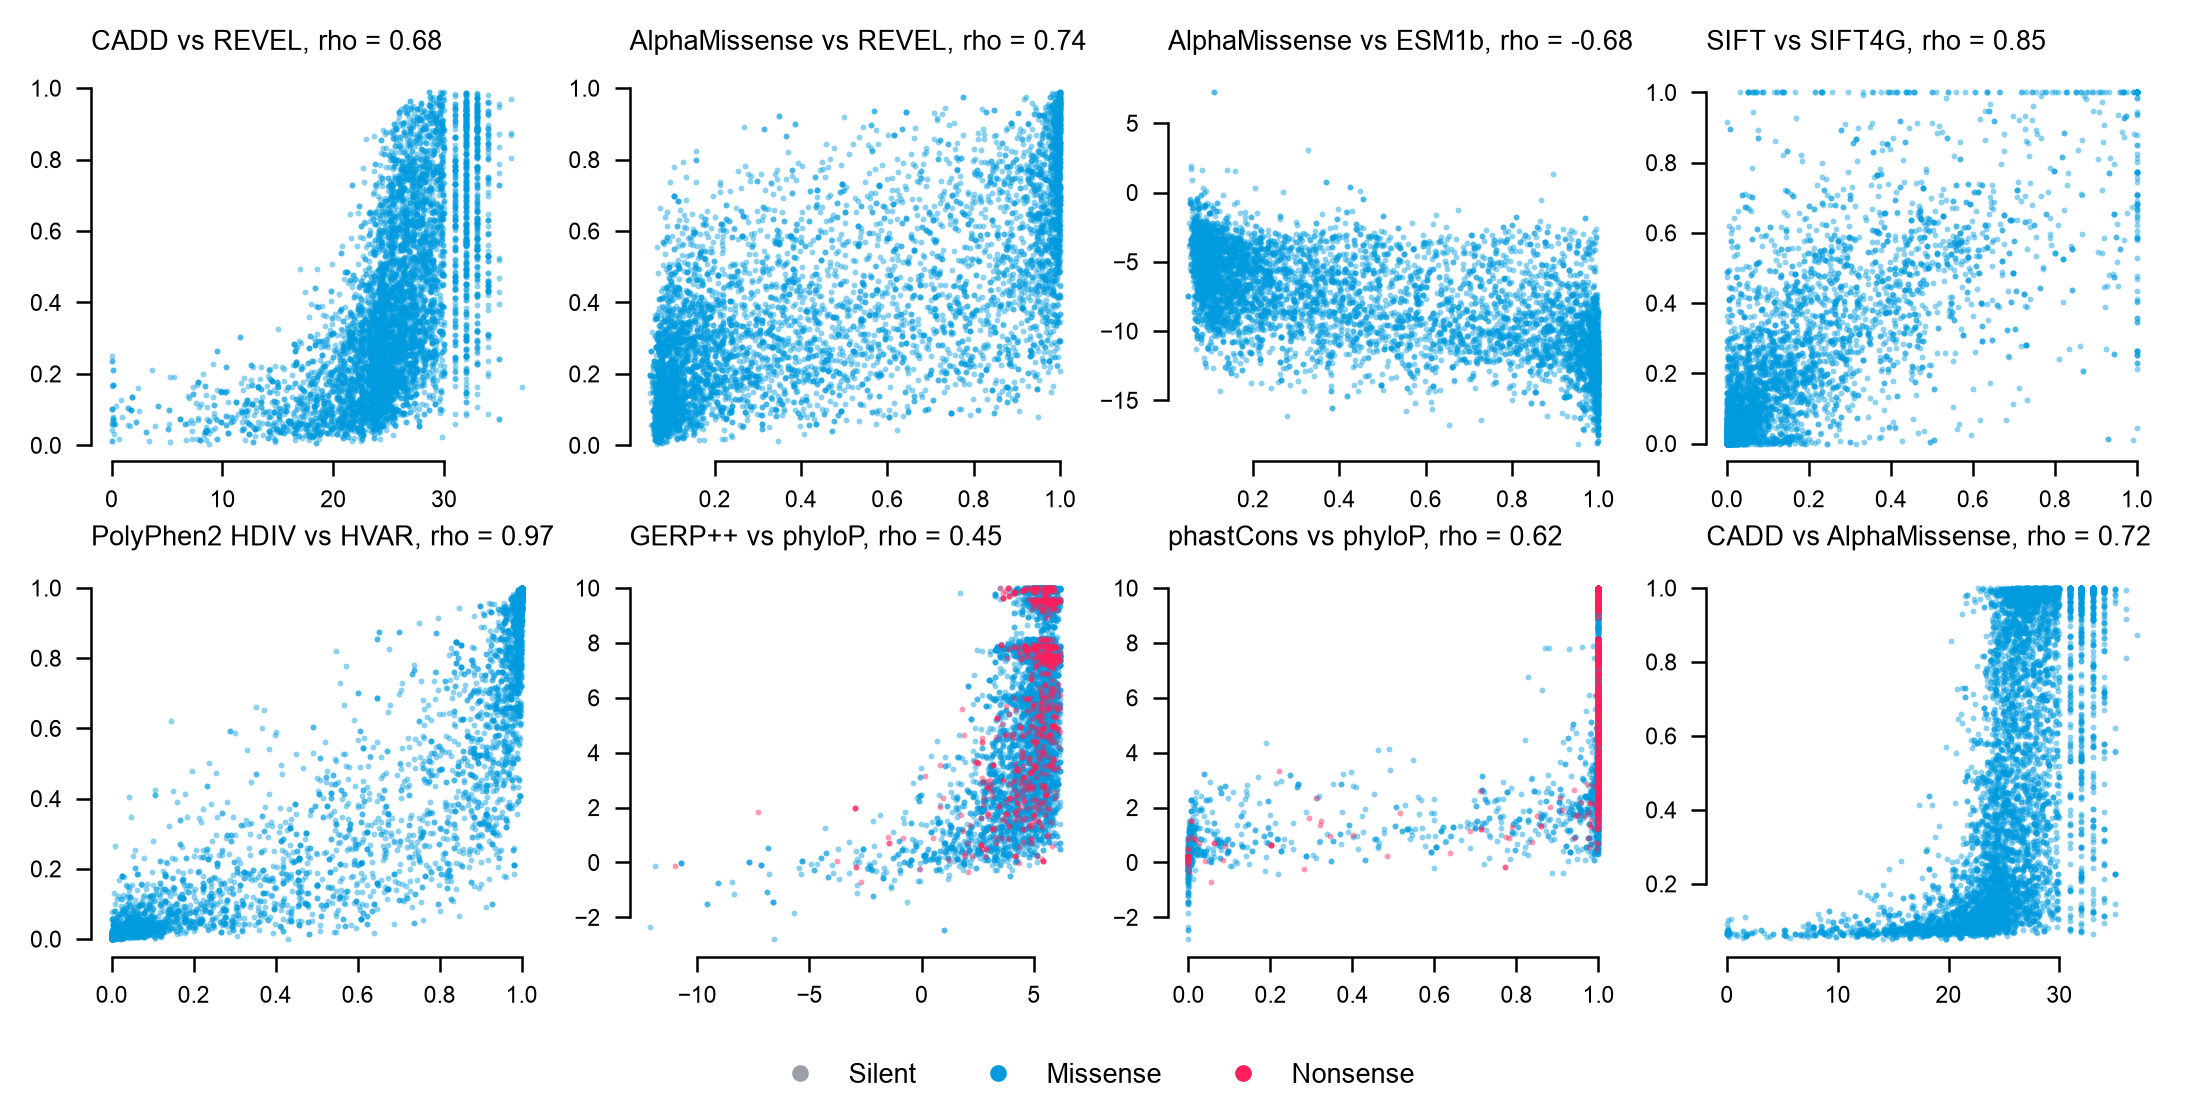

,spearman,n
comparison,,
CADD vs REVEL,0.684229,6602
AlphaMissense vs REVEL,0.736309,6553
AlphaMissense vs ESM1b,-0.682247,6889
SIFT vs SIFT4G,0.847566,6483
PolyPhen2 HDIV vs HVAR,0.971934,6791
GERP++ vs phyloP,0.452913,7661
phastCons vs phyloP,0.616895,7661
CADD vs AlphaMissense,0.719584,6889


In [40]:
fig, axes = plt.subplots(2, 4, figsize=(7.2, 3.6))
summary = []
for ax, (first, second, label) in zip(axes.ravel(), present):
    block = pd.DataFrame(
        {
            "x": numeric(first),
            "y": numeric(second),
            "category": variants.codon_mutation_category,
        }
    ).dropna()
    rho = block.x.corr(block.y, method="spearman")
    summary.append({"comparison": label, "spearman": rho, "n": len(block)})
    for category in ["Silent", "Missense", "Nonsense"]:
        part = block[block.category == category]
        if len(part):
            ax.scatter(part.x, part.y, s=2, linewidths=0, alpha=0.45,
                       color=CATEGORY_COLOUR[category], label=category, rasterized=True)
    ax.set_title(f"{label}, rho = {rho:.2f}", fontsize=6.5, loc="left")
    ax.tick_params(labelsize=5.5)
for ax in axes.ravel()[len(present):]:
    ax.set_visible(False)
handles = [
    plt.Line2D([], [], marker="o", ls="", ms=3, color=CATEGORY_COLOUR[c], label=c)
    for c in ["Silent", "Missense", "Nonsense"]
]
fig.legend(handles=handles, frameon=False, fontsize=6.5, ncol=3, loc="lower center")
fig.tight_layout(pad=0.4, rect=(0, 0.07, 1, 1))
save_plot(fig, "eda_predictor_agreement")
plt.show()
pd.DataFrame(summary).set_index("comparison")

## Collinearity


In [41]:
THRESHOLD = 0.8          # every pair inside a group correlates at least this much
REFERENCE = "vep_CADD_phred"   # a broadly measured feature to orient the others against

In [42]:
matrix = variants[USABLE].apply(pd.to_numeric, errors="coerce")
matrix = matrix.loc[:, matrix.nunique() > 1]

In [43]:
matrix

,vep_gnomADe_AF,vep_gnomADe_AFR_AF,vep_gnomADe_AMR_AF,vep_gnomADe_EAS_AF,vep_gnomADe_NFE_AF,vep_gnomADe_REMAINING_AF,vep_gnomADe_SAS_AF,vep_MAX_AF,vep_am_pathogenicity,vep_AlphaMissense_rankscore,...,vep_phyloP17way_primate,vep_phyloP17way_primate_rankscore,vep_phyloP470way_mammalian,vep_phyloP470way_mammalian_rankscore,vep_popEVE_converted_rankscore,vep_popEVE_score,spliceai_ds_ag,spliceai_ds_al,spliceai_ds_dg,spliceai_ds_dl
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.00,0.0,0.0,0.0
9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.4521,0.66817,...,0.676,0.77552,11.678,0.94528,0.73444,-3.672,0.01,0.0,0.0,0.0
19,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0870,0.45055,...,0.676,0.77552,11.676,0.94505,0.10216,-2.859,0.00,0.0,0.0,0.0
20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0870,0.45055,...,0.676,0.77552,11.676,0.94505,0.10216,-2.859,0.00,0.0,0.0,0.0
21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0870,0.45055,...,0.676,0.77552,11.676,0.94505,0.10216,-2.859,0.00,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49999,0.000002,0.0,0.000000,0.0,0.000002,0.000000,0.0,0.000002,0.4302,0.62242,...,0.584,0.32575,NaN,NaN,0.92595,-4.263,0.00,0.0,0.0,0.0
50001,0.000002,0.0,0.000000,0.0,0.000002,0.000000,0.0,0.000002,0.4302,0.62242,...,0.584,0.32575,NaN,NaN,0.92595,-4.263,0.00,0.0,0.0,0.0
50007,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.519,0.25887,NaN,NaN,0.98899,-5.236,0.00,0.0,0.0,0.0
50010,0.000004,0.0,0.000199,0.0,0.000000,0.000055,0.0,0.000199,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.00,0.0,0.0,0.0


### Orientation


In [44]:
orientation = pd.Series(
    {
        column: -1.0 if matrix[column].corr(matrix[REFERENCE], method="spearman") < 0 else 1.0
        for column in matrix.columns
    }
)
oriented = matrix.mul(orientation)
print(f"{int((orientation < 0).sum())} of {len(orientation)} features sign-flipped")

15 of 114 features sign-flipped


In [45]:
spearman = oriented.corr(method="spearman").fillna(0.0)
pearson = oriented.corr(method="pearson").fillna(0.0)
correlation = spearman

### Spearman against Pearson


In [46]:
def trimmed_pearson(first, second, quantile=0.99):
    """Pearson after dropping the most extreme 1% by absolute value."""
    both = oriented[[first, second]].dropna()
    extreme = both.abs().max(axis=1)
    kept = both[extreme <= extreme.quantile(quantile)]
    return kept[first].corr(kept[second])


disagreeing = [
    (first, second)
    for i, first in enumerate(correlation.columns)
    for second in correlation.columns[i + 1 :]
    if pearson.loc[first, second] > THRESHOLD and spearman.loc[first, second] <= THRESHOLD
]

In [47]:
pd.DataFrame(
    [
        {
            "pair": f"{a.replace('vep_', '')} / {b.replace('vep_', '')}",
            "spearman": spearman.loc[a, b],
            "pearson": pearson.loc[a, b],
            "pearson trimmed": trimmed_pearson(a, b),
        }
        for a, b in disagreeing
    ]
).set_index("pair").sort_values("pearson trimmed", ascending=False)

,spearman,pearson,pearson trimmed
pair,,,
CADD_raw / MutationTaster_trees_deleterious,0.706704,0.854828,0.854828
gnomADe_AF / gnomADe_REMAINING_AF,0.614393,0.999725,0.853689
CADD_raw_rankscore / Eigen-PC-raw_coding,0.764792,0.827416,0.814005
CADD_raw_rankscore / Eigen-PC-raw_coding_rankscore,0.764793,0.815270,0.812283
MetaRNN_rankscore / PHACTboost_rankscore,0.799421,0.806789,0.806023
ClinPred_rankscore / Eigen-raw_coding_rankscore,0.795935,0.808785,0.804267
ClinPred_rankscore / Eigen-raw_coding,0.795936,0.805968,0.801926
MetaRNN_rankscore / MutScore_rankscore,0.794337,0.802768,0.799829
gnomADe_REMAINING_AF / MAX_AF,0.556966,0.951760,0.627533


In [48]:
survives = sum(1 for a, b in disagreeing if trimmed_pearson(a, b) > THRESHOLD)
print(f"{len(disagreeing) - survives} of {len(disagreeing)} pairs lose their Pearson when "
      f"trimmed; {survives} keep it")

26 of 33 pairs lose their Pearson when trimmed; 7 keep it


## Correlated groups


In [49]:
tree = linkage(squareform(1 - correlation.to_numpy(), checks=False), method="complete")
groups = pd.Series(fcluster(tree, t=1 - THRESHOLD, criterion="distance"), index=correlation.index)

In [50]:
# one row per group: its members and the weakest correlation inside it
def group_summary(members):
    inside = correlation.loc[members, members].to_numpy()
    off_diagonal = inside[~np.eye(len(members), dtype=bool)]
    return {
        "size": len(members),
        "family": inventory.family[members].mode().iat[0],
        "weakest pair": off_diagonal.min() if len(members) > 1 else np.nan,
        "members": ", ".join(m.replace("vep_", "") for m in members),
    }


correlated = pd.DataFrame(
    [group_summary(list(m.index)) for _, m in groups.groupby(groups)]
).sort_values("size", ascending=False)
correlated.index = range(1, len(correlated) + 1)
correlated[correlated["size"] > 1]

,size,family,weakest pair,members
1,13,pathogenicity,0.803347,"am_pathogenicity, AlphaMissense_rankscore, Alp..."
2,6,pathogenicity,0.864434,"BayesDel_addAF_rankscore, BayesDel_addAF_score..."
3,6,pathogenicity,0.984469,"Eigen-PC-phred_coding, Eigen-PC-raw_coding, Ei..."
4,4,pathogenicity,0.906440,"MisFit_D_rankscore, MisFit_D_score, MisFit_S_r..."
5,4,pathogenicity,0.905192,"Polyphen2_HDIV_rankscore, Polyphen2_HDIV_score..."
6,4,pathogenicity,0.982788,"MutationTaster_rankscore, MutationTaster_score..."
7,4,pathogenicity,0.800063,"MutScore_rankscore, MutScore_score, PHACTboost..."
8,4,pathogenicity,0.865990,"MetaRNN_rankscore, MetaRNN_score, VEST4_ranksc..."
9,4,pathogenicity,0.975792,"MetaLR_rankscore, MetaLR_score, MetaSVM_ranksc..."
10,4,pathogenicity,0.810482,"SIFT4G_converted_rankscore, SIFT4G_score, SIFT..."


In [51]:
# how many independent axes the usable set really spans, by participation ratio. This is
# computed on all usable features, so it does not depend on choosing a representative.
eigenvalues = np.linalg.eigvalsh(correlation.to_numpy())
eigenvalues = eigenvalues[eigenvalues > 0]
effective = eigenvalues.sum() ** 2 / (eigenvalues**2).sum()
print(f"{len(correlation)} features span {effective:.1f} effective dimensions")

114 features span 3.6 effective dimensions


In [52]:
print(f"{len(correlation)} features form {groups.nunique()} groups, of which "
      f"{int((correlated['size'] > 1).sum())} hold more than one feature")
print(f"weakest within-group correlation anywhere: {correlated['weakest pair'].min():.4f}")

114 features form 46 groups, of which 34 hold more than one feature
weakest within-group correlation anywhere: 0.8001


## Feature representation


In [53]:
structural = pd.DataFrame(
    {
        category: block[USABLE].notna().mean()
        for category, block in unique_variants.groupby("category")
    }
)[["Missense", "Silent", "Nonsense"]]

missense_only = structural[(structural.Missense > 0.8) & (structural.Silent < 0.01)]
print(
    f"{len(missense_only)} of {len(USABLE)} features are measured for missense "
    f"edits and absent for silent ones"
)
print(
    f"  of those, {int((missense_only.Nonsense < 0.01).sum())} are absent for nonsense "
    f"edits as well"
)
everywhere = structural[structural.min(axis=1) > 0.8]
print(f"{len(everywhere)} measured across all three categories: "
      f"{', '.join(f.replace('vep_', '') for f in everywhere.index)}")

98 of 114 features are measured for missense edits and absent for silent ones
  of those, 56 are absent for nonsense edits as well
4 measured across all three categories: spliceai_ds_ag, spliceai_ds_al, spliceai_ds_dg, spliceai_ds_dl


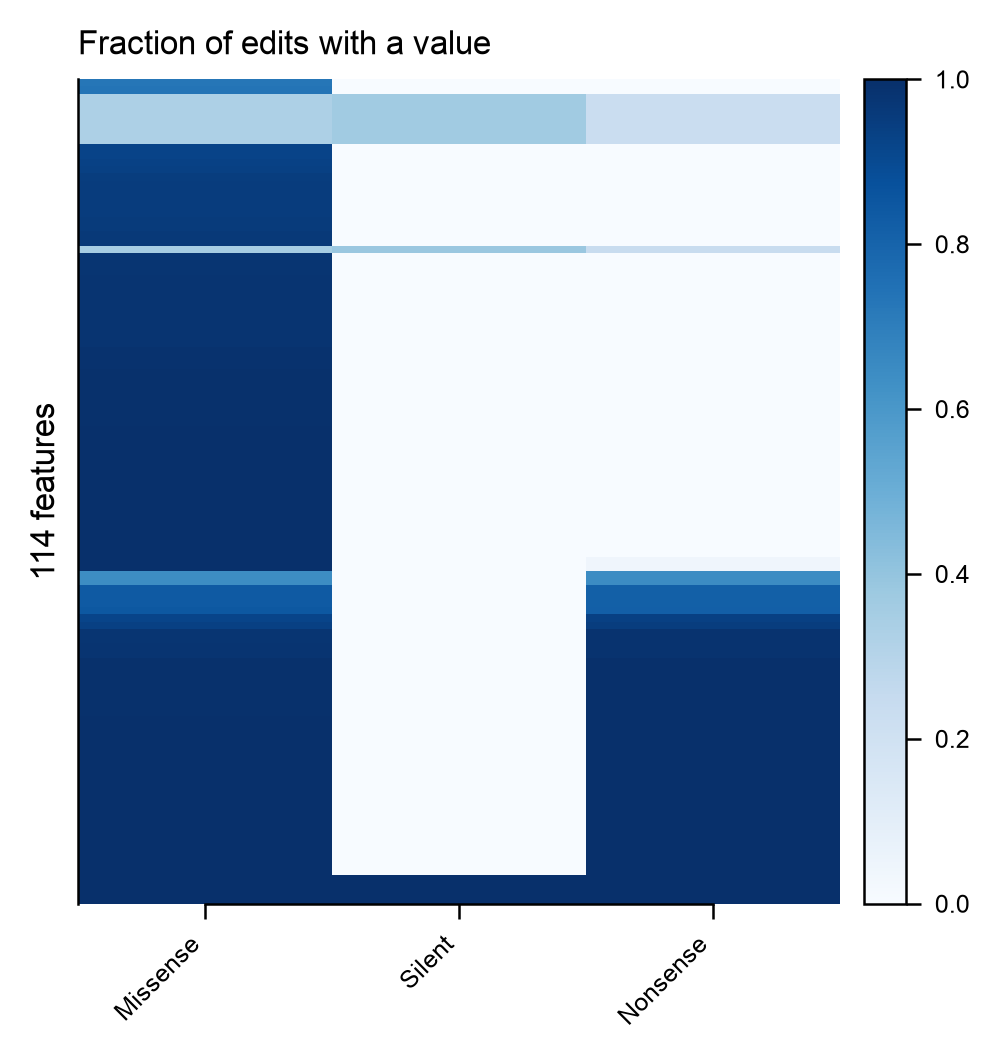

In [54]:
fig, ax = plt.subplots(figsize=(3.2, 3.4))
order = structural.mean(axis=1).sort_values().index
image = ax.imshow(structural.loc[order], cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(structural.shape[1]))
ax.set_xticklabels(structural.columns, rotation=45, ha="right", fontsize=6)
ax.set_yticks([])
ax.set_ylabel(f"{len(order)} features")
ax.set_title("Fraction of edits with a value", fontsize=8, loc="left")
fig.colorbar(image, ax=ax, fraction=0.05, pad=0.03).ax.tick_params(labelsize=6)
fig.tight_layout(pad=0.3)
save_plot(fig, "eda_structural_missingness")
plt.show()

In [55]:
numeric_usable = variants[USABLE].apply(pd.to_numeric, errors="coerce")
shape = pd.DataFrame(
    {
        "skewness": numeric_usable.skew(),
        "zero_share": (numeric_usable == 0).sum() / numeric_usable.notna().sum(),
        "max": numeric_usable.max(),
    }
)
shape["family"] = [inventory.family.get(f, "other") for f in shape.index]
heavy = shape[shape.skewness.abs() > 3].sort_values(
    "skewness", key=abs, ascending=False
)
print(f"{len(heavy)} of {len(shape)} features are strongly skewed (|skew| > 3)")
heavy[["family", "skewness", "zero_share", "max"]].head(8)

17 of 114 features are strongly skewed (|skew| > 3)


,family,skewness,zero_share,max
vep_gnomADe_EAS_AF,frequency,31.969001,0.825346,0.8995
vep_gnomADe_SAS_AF,frequency,28.092176,0.705005,0.8236
vep_gnomADe_NFE_AF,frequency,27.848651,0.263685,0.7314
vep_gnomADe_AMR_AF,frequency,27.747823,0.790628,0.8520
vep_gnomADe_AF,frequency,27.680331,0.058573,0.7359
vep_gnomADe_REMAINING_AF,frequency,27.398747,0.709904,0.7295
vep_MAX_AF,frequency,23.110213,0.050851,0.9187
vep_gnomADe_AFR_AF,frequency,21.866981,0.794036,0.6864


In [56]:
shape.groupby("family").skewness.agg(["mean", "max"])

,mean,max
family,,
conservation,-1.753145,-0.132205
frequency,26.964240,31.969001
other,0.319231,0.319231
pathogenicity,-0.154824,4.165571
splice,7.604047,8.694198


In [57]:
redundant_calls = []
for column in inventory[inventory.kind == "categorical"].index:
    partner = f"vep_{re.sub(r'_pred$', '', column.replace('vep_', ''))}_score"
    if partner not in variants.columns:
        continue
    block = pd.DataFrame(
        {
            "call": variants[column],
            "score": pd.to_numeric(variants[partner], errors="coerce"),
        }
    ).dropna()
    if len(block) < 100 or block.call.nunique() < 2:
        continue
    groups_by_call = [g.score for _, g in block.groupby("call") if len(g) > 5]
    total = block.score.std()
    if len(groups_by_call) < 2 or not total:
        continue
    # the reference point is a pure threshold on the score at the same class balance
    share = (block.call == block.call.mode().iat[0]).mean()
    cut = block.score.quantile(1 - share)
    halves = [block.score[block.score <= cut], block.score[block.score > cut]]
    redundant_calls.append(
        {
            "feature": column.replace("vep_", ""),
            "classes": block.call.nunique(),
            "within/total": float(np.mean([g.std() for g in groups_by_call]) / total),
            "a threshold gives": float(
                np.mean([g.std() for g in halves if len(g) > 5]) / total
            ),
            "n": len(block),
        }
    )

## Correlation map


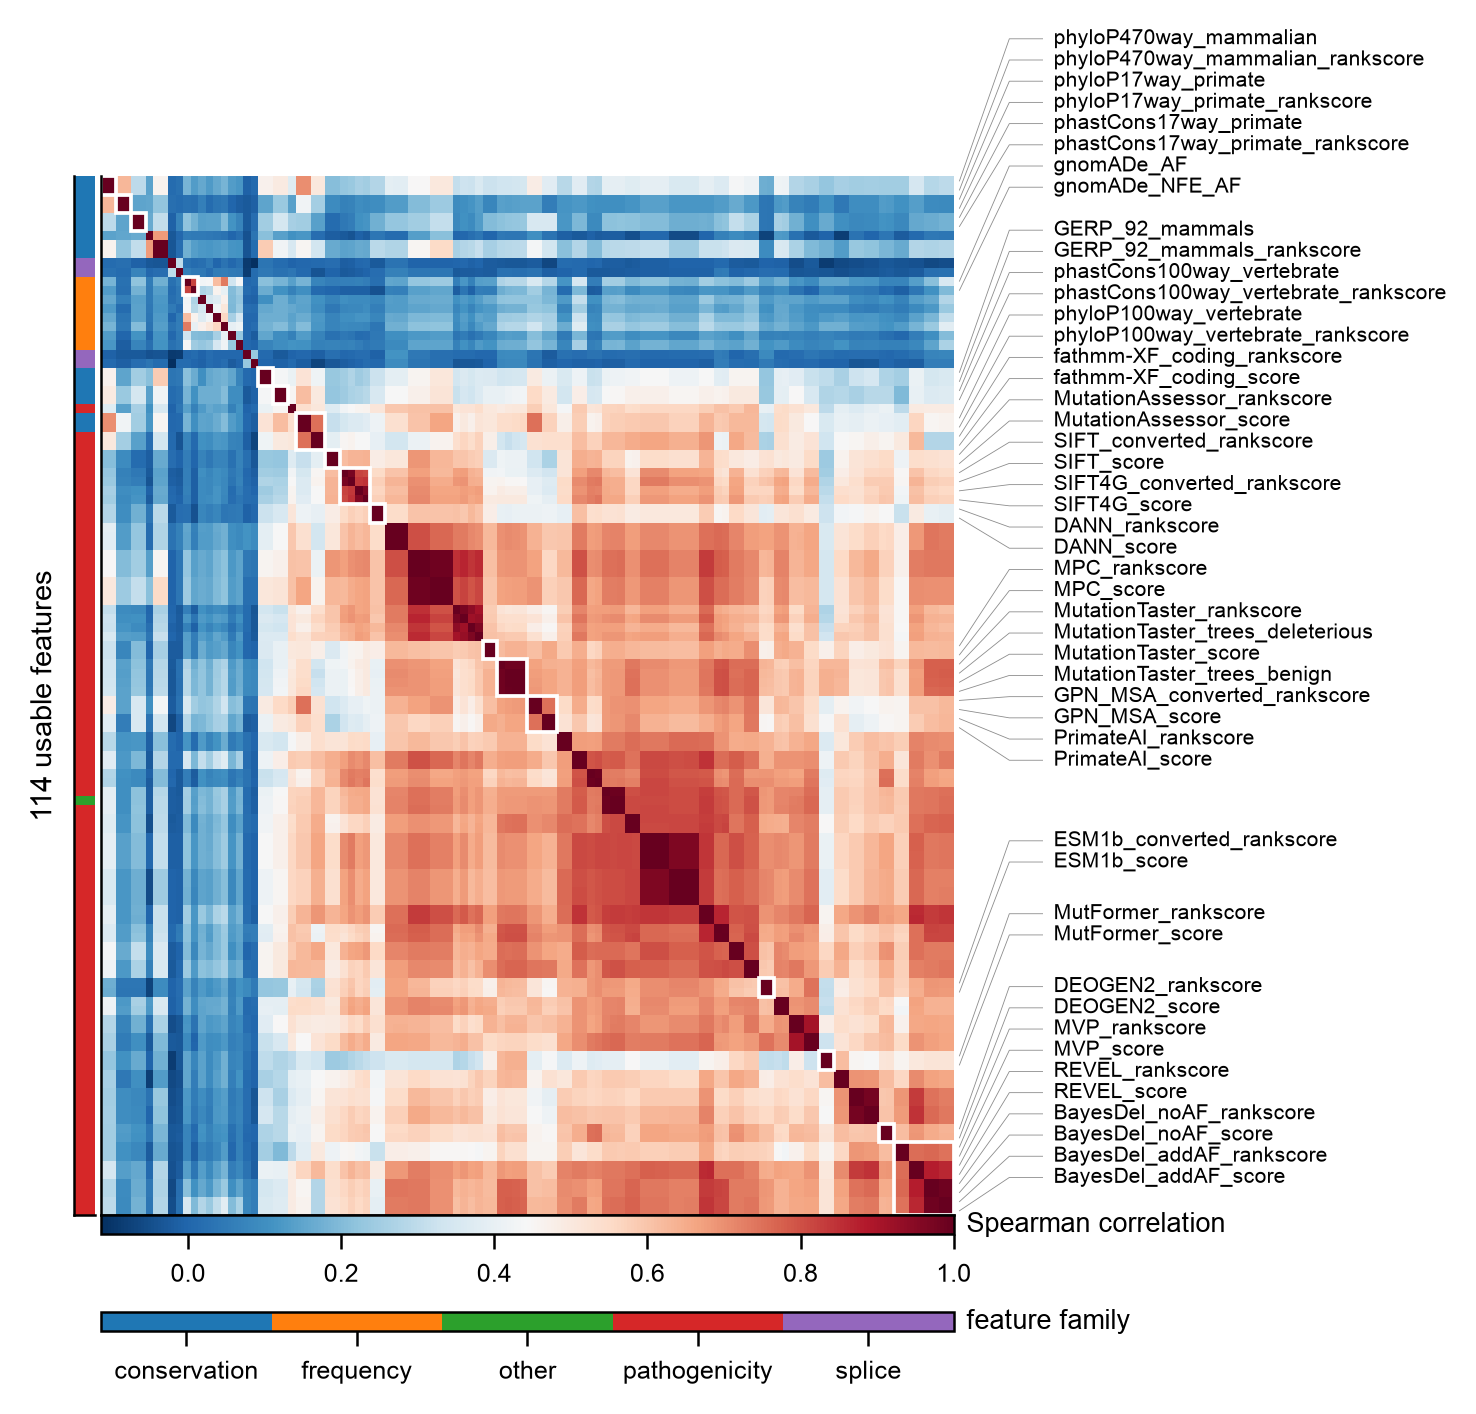

In [85]:
HIGHLIGHT = 0.65       
MAX_LABELS = 50        
LABEL_FONT = 5.0

order = [correlation.index[i] for i in leaves_list(tree)]
ordered = correlation.loc[order, order]

highlight_groups = pd.Series(
    fcluster(tree, t=1 - HIGHLIGHT, criterion="distance"), index=correlation.index
).reindex(order)

candidates, position = [], 0
for _, run in itertools.groupby(highlight_groups):
    size = len(list(run))
    if size > 1:
        inside = ordered.iloc[position : position + size, position : position + size]
        off = inside.to_numpy()[~np.eye(size, dtype=bool)]
        candidates.append({"begin": position, "size": size, "strength": off.mean()})
    position += size

# the most tightly correlated groups are the ones worth marking, taken in that order
# until the label budget is spent
blocks, budget = [], MAX_LABELS
for group in sorted(candidates, key=lambda g: -g["strength"]):
    if group["size"] <= budget:
        blocks.append((group["begin"], group["size"]))
        budget -= group["size"]
blocks.sort()

labelled = [
    (begin + offset, order[begin + offset].replace("vep_", ""))
    for begin, size in blocks
    for offset in range(size)
]

families = sorted(inventory.family[order].dropna().unique())
palette = dict(zip(families, plt.cm.tab10.colors))
family_index = inventory.family[order].map({f: i for i, f in enumerate(families)})

fig = plt.figure(figsize=(5, 5))
grid = fig.add_gridspec(
    4, 3, width_ratios=[1, 40, 13], height_ratios=[60, 1.1, 4.5, 1.1],
    hspace=0.0, wspace=0.015,
)
ax_strip = fig.add_subplot(grid[0, 0])
ax_map = fig.add_subplot(grid[0, 1])
ax_labels = fig.add_subplot(grid[0, 2], sharey=ax_map)
cax_correlation = fig.add_subplot(grid[1, 1])
fig.add_subplot(grid[2, 1]).axis("off")      # spacer, keeps the two scales apart
cax_family = fig.add_subplot(grid[3, 1])

strip = ax_strip.imshow(
    family_index.to_numpy().reshape(-1, 1), aspect="auto",
    cmap=mcolors.ListedColormap([palette[f] for f in families]),
    vmin=-0.5, vmax=len(families) - 0.5,
)
ax_strip.set_xticks([])
ax_strip.set_yticks([])
ax_strip.set_ylabel(f"{len(order)} usable features", fontsize=7)

# the colour scale spans the values actually present, not a nominal -1 to 1
off_diagonal = ordered.to_numpy()[~np.eye(len(order), dtype=bool)]
image = ax_map.imshow(
    ordered.to_numpy(), cmap="RdBu_r",
    vmin=float(off_diagonal.min()), vmax=float(off_diagonal.max()), aspect="auto",
)
for begin, size in blocks:
    ax_map.add_patch(
        plt.Rectangle((begin - 0.5, begin - 0.5), size, size,
                      fill=False, edgecolor="white", lw=0.9)
    )
ax_map.set_xticks([])
ax_map.set_yticks([])


def spread(values, gap, low, high):
    """Push labels apart to `gap`, keeping their order and staying inside the panel.

    If they cannot all fit at that gap it shrinks to what the panel allows, which beats
    clipping: clipping silently stacks labels against the edges.
    """
    out = np.asarray(values, dtype=float).copy()
    if len(out) > 1:
        gap = min(gap, (high - low) / (len(out) - 1))
    out[0] = max(out[0], low)
    for i in range(1, len(out)):
        out[i] = max(out[i], out[i - 1] + gap)
    if out[-1] > high:
        out -= out[-1] - high
    for i in range(len(out) - 2, -1, -1):
        out[i] = min(out[i], out[i + 1] - gap)
    return out


# one line of text occupies this many matrix rows, so labels cannot sit closer
panel_height = ax_map.get_position().height * fig.get_figheight()
gap = len(order) * (LABEL_FONT * 1.6 / 72) / panel_height

rows = [position for position, _ in labelled]
# a margin at the foot keeps the last name clear of the colourbar's label
targets = spread(rows, gap, 0, len(order) - 1 - gap)

ax_labels.set_xlim(0, 1)
ax_labels.set_ylim(ax_map.get_ylim())
ax_labels.axis("off")
for row, target, (_, name) in zip(rows, targets, labelled):
    ax_labels.plot(
        [0.0, 0.18, 0.30], [row, target, target],
        color="0.55", lw=0.2, clip_on=False, solid_joinstyle="round",
    )
    ax_labels.text(0.34, target, name, fontsize=LABEL_FONT, va="center", ha="left")

correlation_bar = fig.colorbar(image, cax=cax_correlation, orientation="horizontal")
correlation_bar.ax.tick_params(labelsize=6)
# the name sits beside the bar rather than under it, where the tick labels already are
cax_correlation.text(1.015, 0.5, "Spearman correlation", transform=cax_correlation.transAxes,
                     ha="left", va="center", fontsize=6.5)

family_bar = fig.colorbar(
    strip, cax=cax_family, orientation="horizontal", ticks=range(len(families))
)
family_bar.ax.set_xticklabels(families, fontsize=6)
cax_family.text(1.015, 0.5, "feature family", transform=cax_family.transAxes,
                ha="left", va="center", fontsize=6.5)

save_plot(fig, "eda_correlation_map")
plt.show()


### Missingness map


In [59]:
missing = variants[USABLE].isna()
print(f"{len(USABLE)} features reduce to {len(missing.T.drop_duplicates())} distinct "
      f"missingness patterns")
print(f"{int((~missing.any(axis=1)).sum()):,} of {len(variants):,} variants have every "
      f"feature measured")

114 features reduce to 40 distinct missingness patterns
870 of 14,043 variants have every feature measured


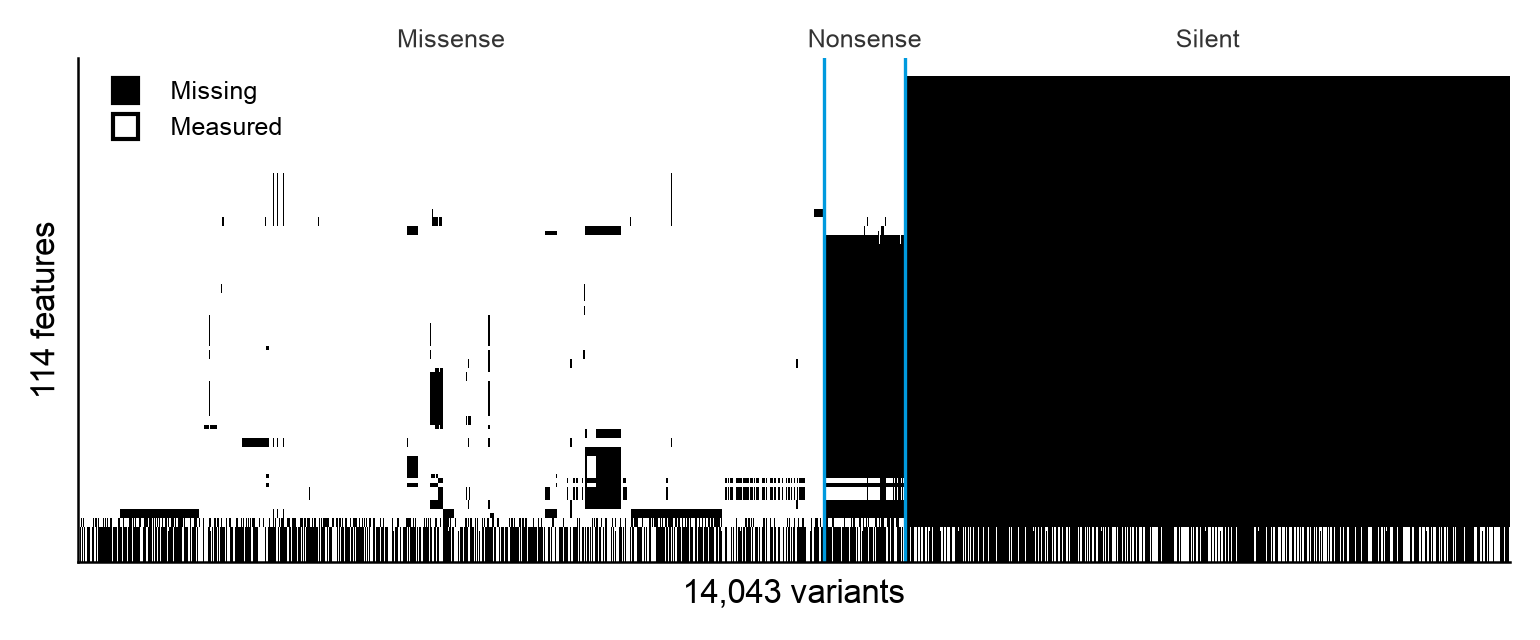

In [88]:
feature_order = missing.mean().sort_values().index
category_order = [c for c in ["Missense", "Nonsense", "Silent"]
                  if c in set(variants.codon_mutation_category)]
column_order = np.concatenate(
    [np.flatnonzero((variants.codon_mutation_category == c).to_numpy())
     for c in category_order]
)
picture = missing.loc[:, feature_order].to_numpy()[column_order].T

fig, ax = plt.subplots(figsize=(5, 2))
ax.imshow(picture, cmap="Greys", vmin=0, vmax=1, aspect="auto", interpolation="nearest")
edge = 0
for category in category_order[:-1]:
    edge += int((variants.codon_mutation_category == category).sum())
    ax.axvline(edge, color="#009ADE", lw=0.8)
centre = 0
for category in category_order:
    width = int((variants.codon_mutation_category == category).sum())
    ax.text(centre + width / 2, -3, category, ha="center", fontsize=6, color="#333333")
    centre += width
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel(f"{len(variants):,} variants")
ax.set_ylabel(f"{len(USABLE)} features")
legend_handles = [
    plt.Line2D([], [], marker="s", linestyle="", color="black", label="Missing"),
    plt.Line2D([], [], marker="s", linestyle="", markerfacecolor="white",
               markeredgecolor="black", label="Measured"),
]
ax.legend(handles=legend_handles, loc="upper left", fontsize=6, frameon=False)
fig.tight_layout(pad=0.3)
save_plot(fig, "eda_missingness_map")
plt.show()

## Distributions by consequence


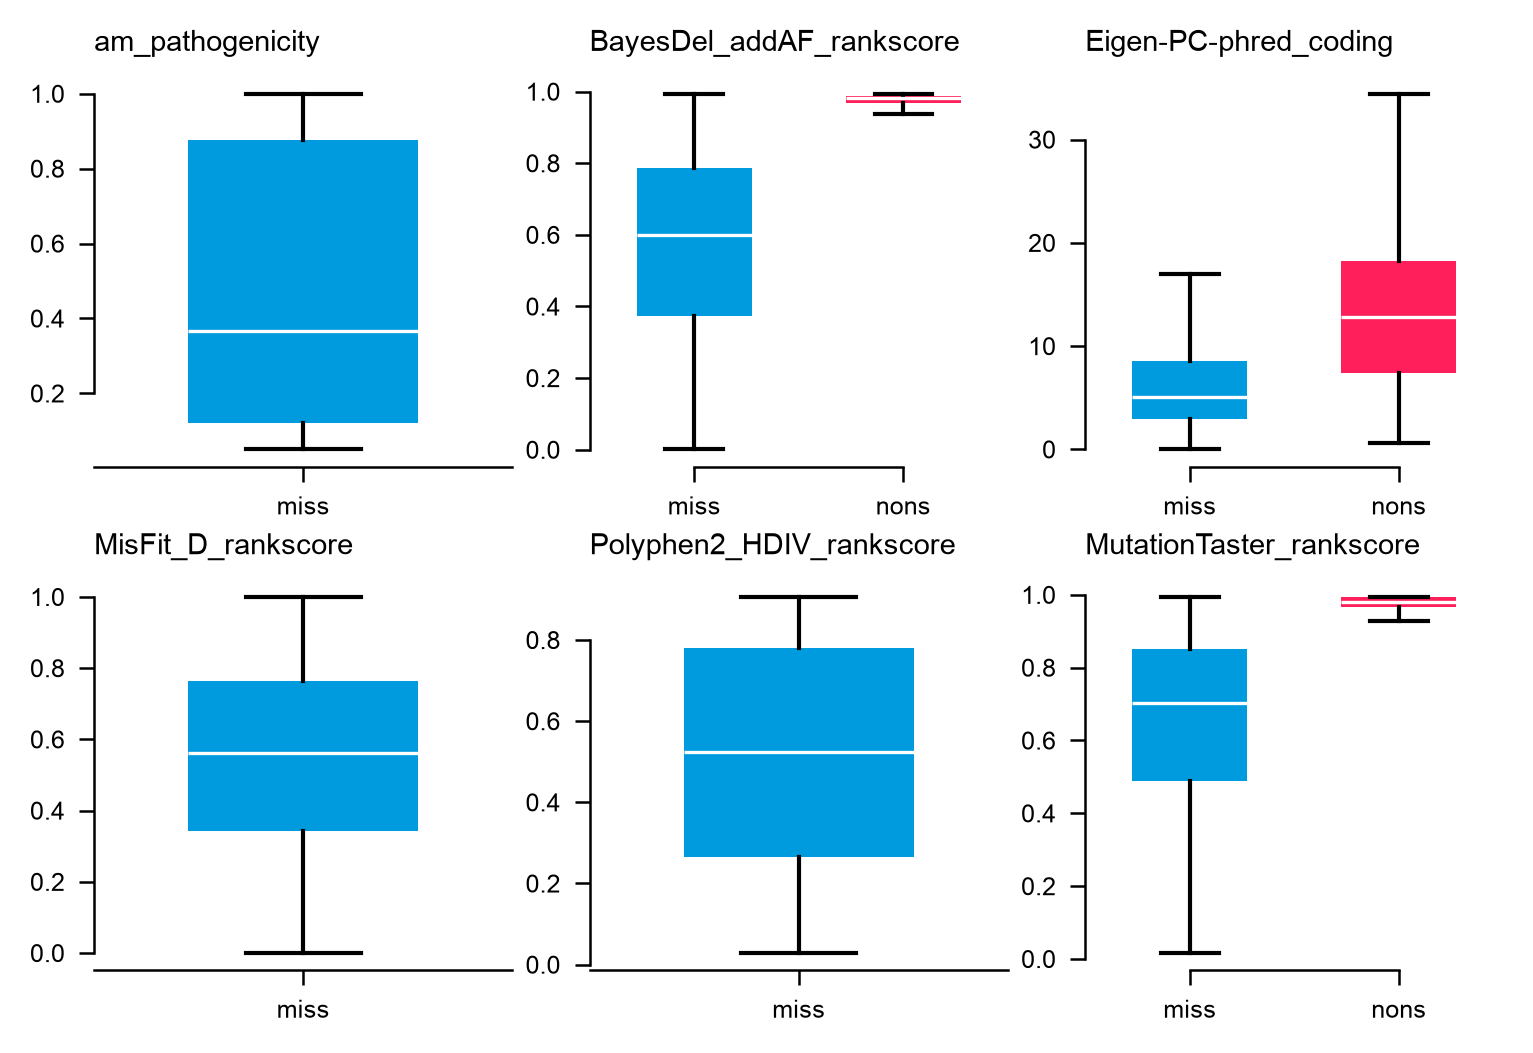

In [61]:
largest = correlated[correlated["size"] > 1].head(6)
shown = []
# the first member of each of the largest groups, as a stand-in for that axis
for position in largest.index:
    shown.append(largest.loc[position, "members"].split(", ")[0])
shown = [f"vep_{name}" if f"vep_{name}" in variants.columns else name for name in shown]
shown = [f for f in shown if f in variants.columns][:6]

fig, axes = plt.subplots(2, 3, figsize=(5.0, 3.4))
for ax, feature in zip(axes.ravel(), shown):
    data, labels, colours = [], [], []
    for category in ["Silent", "Missense", "Nonsense"]:
        block = variants[variants.codon_mutation_category == category]
        values = pd.to_numeric(block[feature], errors="coerce").dropna()
        if len(values) >= 20:
            data.append(values.to_numpy())
            labels.append(category[:4].lower())
            colours.append(CATEGORY_COLOUR[category])
    parts = ax.boxplot(data, widths=0.55, patch_artist=True, showfliers=False,
                       medianprops=dict(color="white", lw=0.8))
    for patch, colour in zip(parts["boxes"], colours):
        patch.set_facecolor(colour)
        patch.set_linewidth(0)
    ax.set_xticklabels(labels, fontsize=6)
    ax.set_title(feature.replace("vep_", ""), fontsize=7, loc="left")
    ax.tick_params(labelsize=6)
for ax in axes.ravel()[len(shown):]:
    ax.set_visible(False)
fig.tight_layout(pad=0.4)
save_plot(fig, "eda_distributions_by_consequence")
plt.show()

## Summary


In [62]:
report = inventory[
    ["family", "kind", "coverage", "distinct", "positional", "modal_share",
     "present_modal_share", "gene_variance", "values_per_gene", "status"]
].copy()
report["correlation_group"] = [groups.get(f, np.nan) for f in report.index]
report["group_size"] = [
    int((groups == groups[f]).sum()) if f in groups.index else np.nan for f in report.index
]
report.index = [f.replace("vep_", "") for f in report.index]
report = report.sort_values(["status", "family", "coverage"], ascending=[True, True, False])
report.to_csv(C.DATA / "features_annotation_inventory.csv")

In [65]:
report

,family,kind,coverage,distinct,positional,modal_share,present_modal_share,gene_variance,values_per_gene,status,correlation_group,group_size
CLIN_SIG,clinical,text,0.222744,97,False,NaN,NaN,NaN,NaN,coverage below 30%,NaN,NaN
clinvar_id,clinical,continuous,0.133091,1416,False,NaN,NaN,NaN,NaN,coverage below 30%,NaN,NaN
clinvar_clnsig,clinical,categorical,0.132094,9,False,NaN,NaN,NaN,NaN,coverage below 30%,NaN,NaN
clinvar_trait,clinical,text,0.132094,347,False,NaN,NaN,NaN,NaN,coverage below 30%,NaN,NaN
clinvar_MedGen_id,clinical,text,0.131169,324,False,NaN,NaN,NaN,NaN,coverage below 30%,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
GENE_PHENO,clinical,binary,0.890550,1,False,NaN,NaN,NaN,NaN,single valued,NaN,NaN
VARIANT_CLASS,other,categorical,1.000000,1,False,NaN,NaN,NaN,NaN,single valued,NaN,NaN
SYMBOL_SOURCE,other,categorical,1.000000,1,False,NaN,NaN,NaN,NaN,single valued,NaN,NaN
BIOTYPE,other,categorical,1.000000,1,False,NaN,NaN,NaN,NaN,single valued,NaN,NaN


In [64]:
report["status"].value_counts()

status
coverage below 30%          351
kept                        114
positional or identifier     49
no values                    37
not numeric                  32
near constant                10
single valued                 5
gene or transcript level      2
Name: count, dtype: int64